In [3]:
import sys
sys.path.append("../src")

import numpy as np
from outcomes import draw_outcome

print(draw_outcome())

3.072128196012601


In [4]:
def simulate_fund(n_startups):
    multiples = []

    for i in range(n_startups):
        multiples.append(draw_outcome())

    return np.mean(multiples)

print(simulate_fund(30))
print(simulate_fund(30))
print(simulate_fund(30))

4.3312494043579415
5.5263078360374465
4.808630057867425


In [5]:
funds = []

for i in range(10000):
    funds.append(simulate_fund(30))

funds = np.array(funds)

print("Average TVPI: ", funds.mean())
print("P(losing money): ", (funds<1).mean())
print("P(almeno 3x): ", (funds >= 3).mean())

Average TVPI:  2.7633924815124447
P(losing money):  0.0685
P(almeno 3x):  0.3658


In [6]:
sizes = [5, 10, 20, 30, 50, 100, 200, 1000]
p_lose = []                                   # NEW
p_3x = []                                     # NEW

for n in sizes:
    funds = []
    for i in range(10000):
        funds.append(simulate_fund(n))
    funds = np.array(funds)
    p_lose.append((funds < 1).mean())         # NEW
    p_3x.append((funds >= 3).mean())          # NEW
    print(n, "startup | P(perdere):", (funds < 1).mean(), "| P(3x):", (funds >= 3).mean())

5 startup | P(perdere): 0.3658 | P(3x): 0.2139
10 startup | P(perdere): 0.251 | P(3x): 0.2697
20 startup | P(perdere): 0.1309 | P(3x): 0.3379
30 startup | P(perdere): 0.0695 | P(3x): 0.3723
50 startup | P(perdere): 0.0233 | P(3x): 0.3775
100 startup | P(perdere): 0.0011 | P(3x): 0.3746
200 startup | P(perdere): 0.0 | P(3x): 0.3433
1000 startup | P(perdere): 0.0 | P(3x): 0.2218


## What this means

**From one startup to a fund.** Phase 1 showed that a handful of outliers generate most of the value. A fund that backs too few startups is likely to miss them. A fund that backs too many converges towards the average startup multiple (2.75x), which is below the 3x target LPs expect.

**What we simulate.** For each portfolio size, we simulate 10,000 funds with equal tickets and measure two things: the probability of losing money (TVPI < 1x) and the probability of returning at least 3x.

| Startups per fund | P(TVPI < 1x) | P(TVPI ≥ 3x) |
|---|---|---|
| 5 | 38.3% | 21.0% |
| 10 | 24.6% | 26.3% |
| 20 | 13.2% | 33.3% |
| 30 | 7.3% | 36.6% |
| 50 | 2.4% | 37.3% |
| 100 | 0.2% | 37.5% |
| 200 | 0.0% | 34.8% |
| 1000 | 0.0% | 21.6% |

**Findings.**
- Diversification does not change the expected return (the average TVPI stays at about 2.75x). It only changes the risk.
- The probability of losing money falls steadily as the portfolio grows.
- The probability of reaching 3x rises up to about 30 startups, stays roughly flat between 30 and 100, and then declines. With 10,000 simulated funds, differences of under one point are within simulation noise.
- Around 30 companies, a fund already captures most of the diversification benefit while keeping the best chance of 3x. This is in line with typical seed portfolios of 30-50 companies.

**Limitation.** The model assumes every startup is drawn at random from the same distribution, so the manager has no selection skill. A fund that picks better than average shifts the distribution upwards and can afford a more concentrated portfolio.

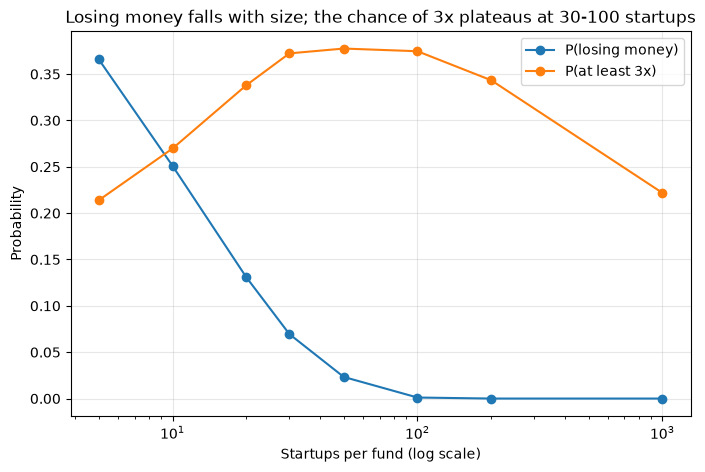

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(sizes, p_lose, marker="o", label="P(losing money)")
plt.plot(sizes, p_3x, marker="o", label="P(at least 3x)")
plt.xscale("log")
plt.xlabel("Startups per fund (log scale)")
plt.ylabel("Probability")
plt.title("Losing money falls with size; the chance of 3x plateaus at 30-100 startups")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../results/phase2_portfolio_size.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
import outcomes

for cap in [100, 1000]:
    outcomes.HOME_RUN_CAP = cap
    startups = np.array([draw_outcome() for _ in range(100000)])
    print("Cap", cap, "| mean single startup:", startups.mean().round(2))

outcomes.HOME_RUN_CAP = 100


Cap 100 | mean single startup: 2.79
Cap 1000 | mean single startup: 10.01


## Sensitivity test: the 100x cap on home runs

The data only tell us that 4% of startups return more than 10x. They say nothing about the upper limit, so the 100x cap is our assumption. To test how much it matters, we change only the cap and keep everything else the same.

| Home-run cap | Mean multiple per startup |
|---|---|
| 100x | 2.73x |
| 1000x | 9.67x |

**The cap drives the result.** With a 1000x cap, half of the home runs would exceed 100x, which means 2% of all startups. A mean of almost 10x per startup would imply that a diversified fund returns about 10x, while top-quartile VC funds typically return around 3x. The 100x cap keeps the model consistent with observed fund returns.

**Limitation and next step.** The cap is a simple way to reflect that very high multiples are increasingly rare. A more realistic model would use a power-law (Pareto) tail instead of a hard cap.